## Project card
**The paper :**  
Elowitz, M. B., Levine, A. J., Siggia, E. D. and Swain, P. S. (2002) Stochastic gene expression in a single cell.   
Science 297(5584):1183-1186.
https://doi.org/10.1126/science.1070919  
  
**The data object :**   
Gene expression in a population of identical cells
  
**The random variable chosen :**  
Intrinsic noise

  
**What the paper does :**    
The paper investigates the relationship between intrinsic noise and mean gene expression. It measures  
the intrinsic noise (n_int) at different mean expression levels (m), and uses these measurements to describe   
how noise depends on expression level. The paper models this relationship as

$$
n_{\mathrm{int}}=\sqrt{\frac{c_1}{m}+c_2}.
$$

where c1 and c2 are model parameters. The parameters are fitted to experimental  
data to describe the decreasing levels of noise for increasing gene activity.

**The generative model proposed :**   
We model the measurement of intrinsic noise in strain M22 and use the analytical formula to calculate  
the rate constant c1 using rng to simulate 1000 observations in order to account for systematic variability.


**Parameters and assumptions :**   
Due to systematic errors we assume the values of intrinsic noise to be normally distributed with mean 0.055 and  
standard deviation 0.0023, chosen such that approximately 95% of observations fall within the reported confidence   
limits 0.051–0.060:

$$
n_{\mathrm{int}} \sim N(0.055, \sigma^2)
$$

where

$$
\sigma \approx \frac{0.060 - 0.051}{2 \times 1.96} \approx 0.0023.
$$



**The forward simulation :**   
We generate 1000 random samples of n_int from the assumed normal distribution using a random number generator.  
For each simulated n_int, we calculate the corresponding value of c1 using the published formula.


**The parameterization / fitting :**   
We identify the simulated n_int that produces a c1 closest to the value reported in the paper and compare it  
to the n_int value that would be expected using only the analytical formula.


**What / if the model adds to the paper :**  
Assess whether the published parameter values are compatible with the data observed in one particular strain.

**Model limitations / how it breaks :**  
The model treats both m and c_2 as fixed whereas in reality they both vary when c1 and n_int vary.

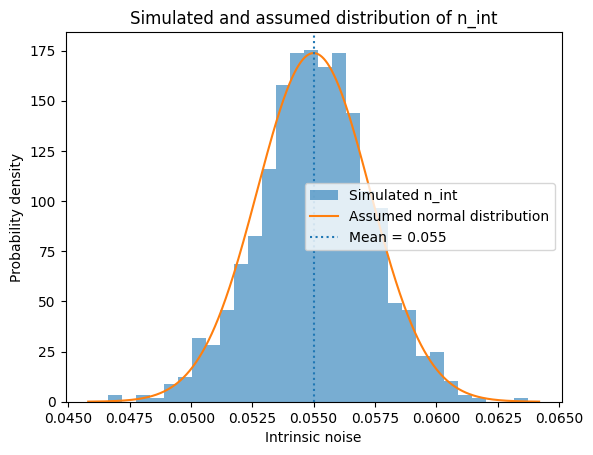

In [41]:
from statistics import NormalDist
import matplotlib.pyplot as plt

# Random number generator
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32

def lcg(state, a, c, m):
    return (a * state + c) % m

def uniforms(k, seed):
    out = [0.0] * k
    state = seed
    for i in range(k):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        out[i] = state / M_LCG
    return out

# Normal distribution of n_int
mean = 0.055
sd = (0.060 - 0.051) / (2 * 1.96)
normal = NormalDist(mean, sd)

# Simulate 1000 n_int values
probabilities = uniforms(1000, seed=12345)
n_int_values = [normal.inv_cdf(p) for p in probabilities]

# Visualize n_int
plt.hist(n_int_values, bins=30, density=True, alpha=0.6, label= 'Simulated n_int')
xs = [mean+sd*z for z in [(-4+8*i/1000) for i in range(1001)]]
ys = [normal.pdf(x) for x in xs]
plt.plot(xs,ys,label= 'Assumed normal distribution')
plt.axvline(mean, linestyle=':', label=f'Mean = {mean}')
plt.xlabel("Intrinsic noise")
plt.ylabel("Probability density")
plt.title("Simulated and assumed distribution of n_int")
plt.legend()
plt.show()

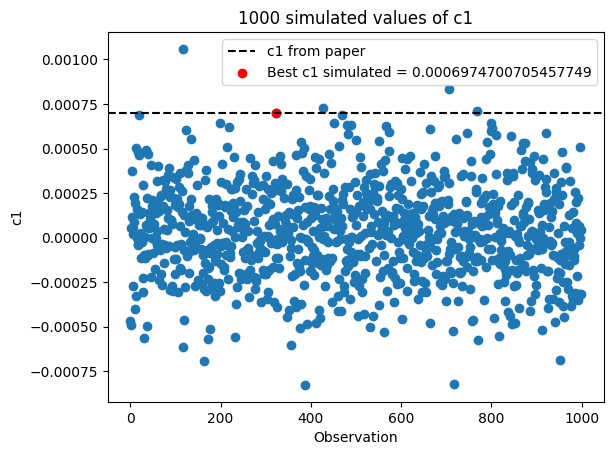

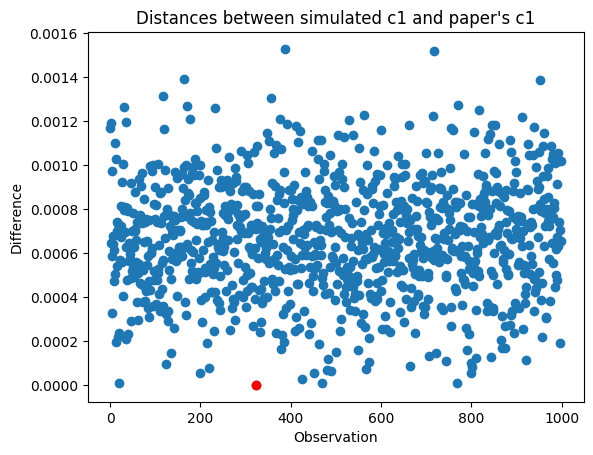

In [36]:
# Calculate c1 for each simulated n_int
m = 1
c2 = 0.003
c1_paper = 0.0007

c1list = []
difflist = []

for n_int in n_int_values:
    c1 = (n_int**2 - c2) * m
    c1list.append(c1)

for c1 in c1list:
    diff = abs(c1 - c1_paper)
    difflist.append(diff)

# Find the simulated n_int for which c1 is the closest one to the paper's c1
best_index = difflist.index(min(difflist))
min_difference = difflist[best_index]
best_n_int_simulated = n_int_values[best_index]

# Calculate n_int using the analytical formula with paper's c1
predicted_n_int = (c1_paper / m + c2) ** 0.5

# Calculate z-score
z_score = (predicted_n_int - mean) / sd

# Calculate upper-tail probability P(n_int >= predicted_n_int)
tail_probability = 1 - normal.cdf(predicted_n_int)

# Visualize simulated c1 values
plt.scatter(range(len(c1list)), c1list)
plt.axhline(c1_paper,linestyle= '--', label= 'c1 from paper', c= 'black')
plt.scatter(best_index, c1list[best_index], color='red', label=f'Best c1 simulated = {c1list[best_index]:}')
plt.xlabel("Observation")
plt.ylabel("c1")
plt.title("1000 simulated values of c1")
plt.legend()
plt.show()

# Visualize distances between sim(c1) and paper's c1
plt.scatter(range(len(difflist)), difflist)
plt.scatter(best_index, difflist[best_index], color='red', label=f'Minimized distance = {min_difference:}')
plt.xlabel("Observation")
plt.ylabel("Difference")
plt.title("Distances between simulated c1 and paper's c1")
plt.show()

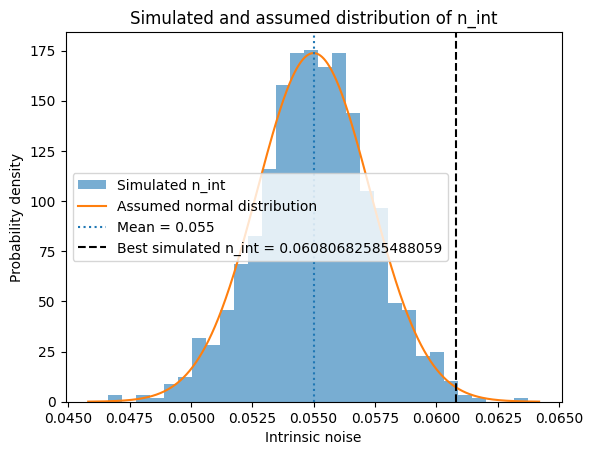

Paper's c1: 0.0007
Simulated c1 closest to paper's c1: 0.0006974700705457749
Difference in c1: 2.5299294542250944e-06
Calculated n_int: 0.0608276253029822
Simulated n_int for which c1 is closest to paper's c1: 0.06080682585488059
z-score: 2.5382545764100235 standard deviations above the expected value
Probability of observing simulated n_int or greater: 0.005570345573203017
Probability (%) of observing n_int or greater: 0.5570345573203017


In [42]:

# Visualize n_int
plt.hist(n_int_values, bins=30, density=True, alpha=0.6, label= 'Simulated n_int')
xs = [mean+sd*z for z in [(-4+8*i/1000) for i in range(1001)]]
ys = [normal.pdf(x) for x in xs]
plt.plot(xs,ys,label= 'Assumed normal distribution')
plt.axvline(mean, linestyle=':', label=f'Mean = {mean}')
plt.axvline(best_n_int_simulated,linestyle='--',color='black', label=f'Best simulated n_int = {best_n_int_simulated}')
plt.xlabel("Intrinsic noise")
plt.ylabel("Probability density")
plt.title("Simulated and assumed distribution of n_int")
plt.legend()
plt.show()

# Summary
print("Paper's c1:", c1_paper)
print("Simulated c1 closest to paper's c1:", c1list[best_index])
print("Difference in c1:", min_difference)
print("Calculated n_int:", predicted_n_int)
print("Simulated n_int for which c1 is closest to paper's c1:", best_n_int_simulated)
print("z-score:", z_score, "standard deviations above the expected value")
print("Probability of observing simulated n_int or greater:", tail_probability)
print("Probability (%) of observing n_int or greater:", tail_probability * 100)